---
# **Multi-Agent System for p53-Targeted Neuroblastoma Hypotheses**

## Joseph Nicolas

---
## ◈ Prerequisites

To run all the code in this Jupyter notebook successfully, the following setup is required:
1) A .env file containing: **`NCBI_KEY`**, **`ELSEVIER_KEY`**, **`ELSEVIER_INST`**, **`NEO4J_URI`**, **`NEO4J_USER`**, **`NEO4J_PASSWORD`**, **`OLLAMA_URL`**, & **`HF_TOKEN`**

2) Run Neo4j in the background through the terminal using the command: **`"neo4j console"`**

3) Run Ollama in the background through the terminal using the command: **`"ollama serve"`**

---
## ◈ Pipeline Outputs

If all prerequisites are met and the code runs successfully, the pipeline saves the following files inside the **`data/`** folder:
1) **`01_pmc_papers.json`**
2) **`02_sciencedirect_papers.json`**
3) **`03_combined_papers.json`**
4) **`04_processed_papers.json`**
5) **`05_ner_papers.json`**
6) **`06_relation_papers.json`**
7) **`07_discussion_results.json`**
8) **`figure01_abstract_wordcloud.png`**
9) **`figure02_entity_distribution.png`**
10) **`figure03_relation_types.png`**

The JSON files are intermediate data sections, while the PNG figures are the visualisations generated from the pipeline.

----

## ◈ Imports

First, I bring in all the necessary libraries and remove any warnings so they don't clutter the output and make things harder to read.

In [1]:
import os
import re
import time
import json
import spacy
import torch
import random
import requests
import scispacy
import warnings
import numpy as np
from tqdm import tqdm
from dotenv import load_dotenv
from neo4j import GraphDatabase
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from ftlangdetect import detect
import xml.etree.ElementTree as ET
from autogen.agentchat import run_group_chat
from autogen import ConversableAgent
from autogen.agentchat.group.patterns import RoundRobinPattern
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

# Ignore warnings for clean output
warnings.filterwarnings("ignore", category=FutureWarning, module="spacy.language",)

----

## ◈ Configuration

I load all our API keys, database credentials, and local model endpoints from the **`.env`** file to keep sensitive details out of the notebook.\
Experiment parameters are also defined here for easy tuning.

In [2]:
# Load environment variables from my .env file
load_dotenv()

# API Keys
PMC_API = os.getenv("NCBI_KEY") # PMC API replaces CORE API
SCIENCEDIRECT_API = os.getenv("ELSEVIER_KEY")
SCIENCEDIRECT_INST = os.getenv("ELSEVIER_INST") # Extra API key needed for ScienceDirect

# Local Neo4j
NEO4J_URI = os.getenv("NEO4J_URI")
NEO4J_USER = os.getenv("NEO4J_USER")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD")

# Local DeepSeek (through Ollama)
OLLAMA_URL = os.getenv("OLLAMA_URL")

# Hugging Face 
HF_TOKEN = os.getenv("HF_TOKEN")

### Experiment Parameters
MAX_PAPERS_PER_QUERY = 50 # Papers to fetch per API query
MAX_ROUNDS = 30 # Max discussion rounds for the agents

----

## ◈ Data Preprocessing

This section handles all the data preprocessing before building the knowledge graph. I pull together research papers from two sources, the **PubMed Central API** and the **ScienceDirect API**, with separate functions for each so I can control how many papers I get per query and what metadata I keep. Once I have the raw papers saved as JSONs, I run them through a processing step that removes any noise generated by the APIs like concatenated section headers, LaTeX commands, and other formatting junk. It also drops any papers with missing or insufficient content. After this cleaning, the papers are ready to go straight into the knowledge graph pipeline.

### ◇ PMC API

Time to gather the actual data. This function queries the PubMed Central API using NCBI's E-utilities, retrieving title, DOI, publication year, abstract, and full text for each matching paper. I'm filtering out non-English articles, skipping anything with insufficient text (under 100 characters), and removing duplicates across search terms using DOIs and normalized titles. The max_results_per_query parameter controls how many papers we aim to collect per search term, with additional pages fetched automatically until we hit that target or run out of results. The output is saved to **`01_pmc_papers.json`**, so I can tweak parameters later without calling the API again.

NCBI Documentation: https://www.ncbi.nlm.nih.gov/books/NBK25497/

In [3]:
def fetch_pmc_papers(queries, api_key, max_results_per_query=3, save_json=True):
    """
    Searches the PubMed Central (PMC) API using NCBI E-utilities for papers matching a list of queries.
    For each result, fetches full XML records and extracts title, DOI, publication year, abstract,
    and full text. Filters out non-English papers and those with short or missing abstracts/full text.
    Continues fetching additional pages until the requested number of valid papers (max_results_per_query)
    are collected or the search results are exhausted. Returns a list of dictionaries with metadata and full_text.
    Saves results to ./data/01_pmc_papers.json.
    """
    base_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"
    pmc_papers = []
    seen = set()  # track DOIs and normalized titles to avoid duplicates across queries

    print("------------------------------------------------------- PubMed Central API -------------------------------------------------------")
    
    # Loop through each search term to fetch papers separately
    for query in queries:
        print(f"Query: '{query}'")
        valid_papers = [] # Will store papers that pass the quality filter
        retmax = 10
        retstart = 0
        total_results = None # To store total number of results for this query

        # Keep fetching until we have enough valid papers or run out of results
        while len(valid_papers) < max_results_per_query:
            # Search for papers matching the current query in the PMC database
            search_url = f"{base_url}/esearch.fcgi?db=pmc&term={query}&retmax={retmax}&retstart={retstart}&retmode=json&api_key={api_key}"
            search_resp = requests.get(search_url)
            
            if search_resp.status_code != 200:
                print(f"⚠️ Search error: {search_resp.status_code}")
                break
                
            search_data = search_resp.json()
            ids = search_data.get("esearchresult", {}).get("idlist", [])
            if not ids:
                break

            # Store total results from first response
            if total_results is None:
                total_results = int(search_data.get("esearchresult", {}).get("count", 0))
            
            # Fetch the full XML records for all the IDs we just found
            fetch_url = f"{base_url}/efetch.fcgi?db=pmc&id={','.join(ids)}&retmode=xml&api_key={api_key}"
            fetch_resp = requests.get(fetch_url)
            
            if fetch_resp.status_code == 200:
                # Parse the XML to extract the title, abstract, year, and full text
                root = ET.fromstring(fetch_resp.content)
                
                # Loop through each article in the XML response
                for article in root.findall(".//article"):
                    # Grab the article title
                    title_elem = article.find(".//article-title")
                    title = ''.join(title_elem.itertext()).strip() if title_elem is not None else ""

                    # Skip any paper with a too-short title (empty or short)
                    if len(title) <= 10:
                        continue
                        
                    # Skip any paper whose title isn't in English
                    lang = detect(text=title, low_memory=True)["lang"]
                    if lang != "en":
                        continue

                    # Extract the DOI if available
                    doi_elem = article.find(".//article-id[@pub-id-type='doi']")
                    doi = doi_elem.text if doi_elem is not None else ""

                    # Deduplicate using DOI (preferred) or normalized title
                    key = doi.lower() if doi else title.lower().strip()
                    if key in seen:
                        continue
                    seen.add(key)
                    
                    # Extract the publication year from the pub-date element
                    year_elem = article.find(".//pub-date")
                    year = ""
                    if year_elem is not None:
                        year_elem = year_elem.find(".//year")
                        if year_elem is not None:
                            year = int(year_elem.text)
                    
                    # Extract the abstract text
                    abstract_elem = article.find(".//abstract")
                    abstract = ""
                    if abstract_elem is not None:
                        abstract = ''.join(abstract_elem.itertext())
                    # Ensure abstract is never None
                    abstract = abstract or ""
                    
                    # Extract the full text content from the body of the article
                    body = article.find(".//body")
                    full_text = ""
                    if body is not None:
                        full_text = ''.join(body.itertext())
                    full_text = full_text or ""

                    # Skip if abstract or full_text are too short or empty
                    if len(abstract.strip()) < 100 or len(full_text.strip()) < 100:
                        continue
                    
                    # Store everything in a dictionary matching our expected format
                    valid_papers.append({
                        "title": title,
                        "doi": doi,
                        "year": year,
                        "source": "PubMed Central",
                        "abstract": abstract.strip(),
                        "full_text": full_text.strip()
                    })
                    
                    # Stop once we've collected enough valid papers for this query
                    if len(valid_papers) >= max_results_per_query:
                        break

            # If we have enough valid papers, break out of the while loop
            if len(valid_papers) >= max_results_per_query:
                break

            # Move to the next page of results
            retstart += retmax
            
            # Stop if we've reached the total number of results
            if total_results is not None and retstart >= total_results:
                break
                
            # Be respectful to the NCBI servers
            time.sleep(0.5)

        print(f" ⤷ Fetched {len(valid_papers)} papers.")
        pmc_papers.extend(valid_papers)

    print(f"🗂️ PubMed Central papers collected: {len(pmc_papers)}.")
    
    # Save everything to JSON so we don't have to hit the API again
    if save_json:
        os.makedirs("./data", exist_ok=True)
        with open("./data/01_pmc_papers.json", "w", encoding="utf-8") as f:
            json.dump(pmc_papers, f, indent=2, ensure_ascii=False)
        print("💾 Saved 01_pmc_papers.json to 'data'.")

    # Print a preview of the first paper to get a look of the data
    if pmc_papers:
        sample = pmc_papers[0]
        print("\nSample paper:")
        print(f" ⤷ title: {sample.get('title')[:100]}...")
        print(f" ⤷ doi: {sample.get('doi')}")
        print(f" ⤷ year: {sample.get('year')}")     
        print(f" ⤷ source: {sample.get('source')}")
        print(f" ⤷ abstract: {sample.get('abstract')[:100]}...")
        print(f" ⤷ full_text: {sample.get('full_text')[:100]}...")
    
    return pmc_papers

Once the cell finishes running, we'll have a nice collection of raw papers saved in the data folder.

**🎯 Note:** This pipeline uses the PubMed Central API instead of CORE, as CORE was unreliable during development. PubMed Central is also a better fit for biomedical literature.

### ◇ ScienceDirect API

Next up, the ScienceDirect API. This function searches the Elsevier ScienceDirect API using the same set of queries, then retrieves full text as plain text and extracts the abstract from the JSON response for each paper with a DOI. Non-English papers are filtered out, and any article with insufficient text (under 100 characters) is discarded. The function keeps fetching pages until we've collected the target number of valid papers per query or run out of results. The output is saved to **`02_sciencedirect_papers.json`** to avoid re‑fetching every time.

ScienceDirect Search API V2 Documentation: https://dev.elsevier.com/documentation/SCIDIRSearchAPI.wadl \
Article (Full Text) Retrieval API Documentation: https://dev.elsevier.com/documentation/ArticleRetrievalAPI.wadl 

In [4]:
def fetch_sciencedirect_papers(queries, api_key, inst_key, max_results_per_query=3, save_json=True):
    """
    Searches the ScienceDirect Search API for papers matching a list of queries.
    For each result, fetches full text via the Article Retrieval API using 'text/plain'
    and extracts the abstract from the JSON response. Filters out non-English papers
    and those with short or missing abstracts/full text. Continues fetching additional pages 
    until the requested number of valid papers (max_results_per_query) are collected or the 
    search results are exhausted. Returns a list of dictionaries with metadata, abstract,
    and full_text. Saves results to ./data/02_sciencedirect_papers.json.
    """
    base_url = "https://api.elsevier.com/content/search/sciencedirect"
    headers = {
        "Accept": "application/json",
        "X-ELS-APIKey": api_key,
        "X-ELS-Insttoken": inst_key
    }
    sciencedirect_papers = []
    seen = set()  # track DOIs and normalized titles to avoid duplicates across queries

    print("\n------------------------------------------------------- ScienceDirect API -------------------------------------------------------")

    # Loop through each search term to fetch papers separately
    for query in queries:
        print(f"Query: '{query}'")
        valid_papers = [] # Will store papers that pass the quality filter
        start = 0
        count = 10
        total_results = None # To store total number of results for this query

        # Keep fetching until we have enough valid papers or run out of results
        while len(valid_papers) < max_results_per_query:
            # Search for papers matching the current query in the ScienceDirect database
            body = {
                "qs": query,
                "count": count,
                "start": start,
            }
            response = requests.put(base_url, json=body, headers=headers)

            if response.status_code != 200:
                print(f"⚠️ Code: {response.status_code} | {response.text[:500]}\n")
                break

            data = response.json()
            results = data.get("results", [])
            if not results:
                break

            # Store total results from first response
            if total_results is None:
                total_results = data.get("totalResults", 0)

            # Process each result as a candidate
            candidates = []  # temporary list for this batch
            for result in results:
                title = result.get("title", "")
                
                # Skip any paper with an empty or too short title
                if len(title) <= 10:
                    continue
                
                # Skip any paper whose title isn't in English
                lang = detect(text=title, low_memory=True)["lang"]
                if lang != "en":
                    continue

                # Extract the DOI if available
                doi = result.get("doi", "")
                if not doi:
                    continue
                
                # Deduplicate using preferably DOI or normalized title
                key = doi.lower() if doi else title.lower().strip()
                if key in seen:
                    continue
                seen.add(key)
                
                # Safe year extraction
                pub_date = result.get("publicationDate", "")
                year = None
                if pub_date and len(pub_date) >= 4:
                    try:
                        year = int(pub_date[:4])
                    except ValueError:
                        year = None

                # Store metadata temporarily including the placeholders for now
                candidates.append({
                    "title": title,
                    "doi": doi,
                    "year": year,
                    "source": "ScienceDirect",
                    "abstract": "",          # Placeholder to be filled next
                    "full_text": ""          # Also a placeholder
                })

            # Now fetch the actual content for each candidate and filter
            for paper in candidates:
                doi = paper["doi"]
                if not doi:
                    continue

                article_url = f"https://api.elsevier.com/content/article/doi/{doi}"

                # First, fetch the full text as plain text
                full_headers = headers.copy()
                full_headers["Accept"] = "text/plain"
                art_resp = requests.get(article_url, headers=full_headers)
                if art_resp.status_code == 200:
                    paper["full_text"] = art_resp.text or ""

                # Then grab the abstract separately by asking for JSON instead
                json_headers = headers.copy()
                json_headers["Accept"] = "application/json"
                json_resp = requests.get(article_url, headers=json_headers)
                if json_resp.status_code == 200:
                    json_data = json_resp.json()
                    
                    # The abstract lives deep inside the nested coredata structure
                    abstract = json_data.get("full-text-retrieval-response", {})\
                                       .get("coredata", {})\
                                       .get("dc:description")
                    paper["abstract"] = abstract or ""

                # Skip if abstract or full_text are too short or empty
                if len(paper["abstract"].strip()) < 100 or len(paper["full_text"].strip()) < 100:
                    continue
                    
                # Add to valid papers
                valid_papers.append(paper)
                # If we have enough, we can stop processing more candidates in this batch
                if len(valid_papers) >= max_results_per_query:
                    break

            # If we have enough valid papers, break out of the while loop
            if len(valid_papers) >= max_results_per_query:
                break

            # Move to the next page
            start += count
            # Stop if we've reached the total number of results
            if total_results is not None and start >= total_results:
                break
                
            # Also stop if we got fewer results than requested (last page)
            if len(results) < count:
                break
                
            # Be polite to the server
            time.sleep(0.8)

        print(f" ⤷ Fetched {len(valid_papers)} papers.")
        sciencedirect_papers.extend(valid_papers)
        
        # Pause briefly before next query
        time.sleep(0.8)

    print(f"🗂️ ScienceDirect papers collected: {len(sciencedirect_papers)}.")

    if save_json:
        os.makedirs("./data", exist_ok=True)
        with open("./data/02_sciencedirect_papers.json", "w", encoding="utf-8") as f:
            json.dump(sciencedirect_papers, f, indent=2, ensure_ascii=False)
        print("💾 Saved 02_sciencedirect_papers.json to 'data'.")

    # Quick check by printing the first paper we collected
    if sciencedirect_papers:
        sample = sciencedirect_papers[0]
        print("\nSample paper:")
        print(f" ⤷ title: {sample.get('title')[:100]}...")
        print(f" ⤷ doi: {sample.get('doi')}")
        print(f" ⤷ year: {sample.get('year')}")     
        print(f" ⤷ source: {sample.get('source')}")
        print(f" ⤷ abstract: {sample.get('abstract')[:100]}...")
        print(f" ⤷ full_text: {sample.get('full_text')[:100]}...")

    return sciencedirect_papers

Now we have papers from both sources. The next step is to combine them into one big list before we move on to cleaning everything up.

### ◇ Call APIs and Combine

Given that I have the fetching functions ready, I can actually get the papers. I'm using the same set of five search queries for both APIs to keep things consistent: a mix of general p53 terms and some more specific ones like apoptosis and neuroblastoma. Each function will grab the papers then I combine everything into one list and save it as **`03_combined_papers.json`**. This way we have all the raw data in one place before moving on to processing the papers.

In [5]:
# These are the search terms we'll use to pull relevant papers from both APIs
queries = [
    "p53 AND neuroblastoma",
    "TP53 AND neuroblastoma", # Notice the boolean searches with the use of AND
    "p53 AND MDM2 AND neuroblastoma",
    "p53 AND apoptosis AND neuroblastoma",
    "TP53 AND apoptosis AND neuroblastoma"
]

# Fetch papers from both sources using our query list
pmc_papers = fetch_pmc_papers(queries, PMC_API, max_results_per_query=MAX_PAPERS_PER_QUERY)
sciencedirect_papers = fetch_sciencedirect_papers(queries, SCIENCEDIRECT_API, SCIENCEDIRECT_INST, max_results_per_query=MAX_PAPERS_PER_QUERY)

print("\n------------------------------------------------------- Combined Papers -------------------------------------------------------")

# Combine the two result sets together into one joined list
combined_papers = pmc_papers + sciencedirect_papers

# Write the complete merged collection to disk so we don't have to fetch again
with open("./data/03_combined_papers.json", "w", encoding="utf-8") as f:
    json.dump(combined_papers, f, indent=2, ensure_ascii=False)

print(f"🗂️ Total papers collected: {len(combined_papers)}.")
print("💾 Saved 03_combined_papers.json to 'data'.")

------------------------------------------------------- PubMed Central API -------------------------------------------------------
,Query: 'p53 AND neuroblastoma'
, ⤷ Fetched 50 papers.
,Query: 'TP53 AND neuroblastoma'
, ⤷ Fetched 50 papers.
,Query: 'p53 AND MDM2 AND neuroblastoma'
, ⤷ Fetched 50 papers.
,Query: 'p53 AND apoptosis AND neuroblastoma'
, ⤷ Fetched 50 papers.
,Query: 'TP53 AND apoptosis AND neuroblastoma'
, ⤷ Fetched 50 papers.
,🗂️ PubMed Central papers collected: 250.
,💾 Saved 01_pmc_papers.json to 'data'.
,
,Sample paper:
, ⤷ title: Loss of the USP22 deubiquitylase confers resistance to chemotherapy in small cell lung cancer...
, ⤷ doi: 10.1038/s41467-026-75117-2
, ⤷ year: 2026
, ⤷ source: PubMed Central
, ⤷ abstract: Small cell lung cancer (SCLC) responds exceptionally well to cytotoxic chemotherapy. However, relaps...
, ⤷ full_text: IntroductionSmall cell lung cancer (SCLC) is a highly lethal, neuroendocrine lung carcinoma characte...
,
,-------------------------------

There is now a single JSON file containing all the papers from both sources. ScienceDirect came back with fewer papers than requested, 76 total instead of 250, likely due to stricter rate limits or less available content, but that is fine for our purposes. In fact that is one of the unreliabilities with using APIs. Next up is processing the text to remove metadata noise in our papers.

### ◇ Process Text

Next I need to clean the papers before anything else can happen. The publisher metadata tends to be all over the place with DOIs, URLs, copyright statements, XML tags, LaTeX commands, and other junk that would just confuse the NLP models later on. This function runs a whole bunch of regex patterns over the title, abstract, and full text to strip out that noise. It also removes concatenated section headers (e.g., "IntroductionSmall" → "Small") so we're left with just the actual scientific text. The processed version is saved as **`04_processed_papers.json`** so we have a nice tidy corpus to work with.

In [6]:
def process_papers(papers, save_json=True):
    r"""
    Processes title, abstract, and full_text.

    Processing steps applied to each text field:
      - Replace non‑breaking spaces, newlines, tabs, and carriage returns with normal spaces.
      - Remove concatenated section headers when attached directly to a word
        (e.g., "IntroductionSmall" → "Small"). Headers that are followed by a space are kept.
      - Remove Elsevier API URLs (https://api.elsevier.com/...).
      - Remove DOIs (with or without 'doi:' prefix).
      - Remove article IDs (1-s2.0-...).
      - Remove PII / publisher item identifiers (e.g., S0006-291X(25)00658-8).
      - Remove date patterns (YYYY-MM-DD, month names, MM/DD/YYYY).
      - Remove copyright and publishing statements (e.g., "© 2025 Elsevier Inc.", "All rights reserved", "Published by Elsevier B.V.", "The Authors.").
      - Remove journal metadata tokens (e.g., "Journal sco ...", "text/plain", "fla").
      - Remove LaTeX commands and environments (\documentclass, \usepackage, \begin{...}, \end{...}, and standalone \command).
      - Remove XML‑like tags (<...>) and HTML entities (&...;).
      - Remove standalone long numbers (5 or more digits).
      - Remove Volume/Issue/Part labels (e.g., "Volume 769, Issue 4").
      - Remove repeated adjacent words (e.g., "Elsevier Inc. Elsevier Inc.").
      - Collapse multiple whitespace and strip.

    Saves processed data to ./data/04_processed_papers.json.
    """
    def clean_text(s):
        """Apply all regex‑based cleaning steps to a single string."""
        if not isinstance(s, str):
            return ""

        # 1. Replace common troublesome whitespace characters with normal spaces
        s = s.replace('\u00a0', ' ')  # non‑breaking space
        s = s.replace('\n', ' ').replace('\r', ' ').replace('\t', ' ')

        # 2. Remove concatenated section headers when attached directly to a word.
        section_headers = [
            'Introduction', 'Methods', 'Results', 'Discussion', 'Conclusion',
            'Abstract', 'Background', 'Materials', 'Summary', 'References',
            'Acknowledgments', 'Funding', 'Conflicts', 'Supplementary', 'Appendix'
        ]
        for h in section_headers:
            # Match the header immediately followed by a word (no space in between)
            # and replace with just the captured word (keep the word, drop the header).
            s = re.sub(rf'\b{h}(\w+)', r'\1', s, flags=re.IGNORECASE)

        # 3. Remove Elsevier API URLs
        s = re.sub(r'https?://api\.elsevier\.com/content/article/\S+', ' ', s)

        # 4. Remove DOIs (with or without 'doi:' prefix)
        s = re.sub(r'doi:10\.\d{4,9}/[^\s]+', ' ', s)
        s = re.sub(r'10\.\d{4,9}/[^\s]+', ' ', s)

        # 5. Remove article IDs (1-s2.0-...)
        s = re.sub(r'1-s2\.0-\S+', ' ', s)

        # 6. Remove PII / publisher item identifiers (e.g., S0006-291X(25)00658-8)
        s = re.sub(r'S\d{4}-\d{4}\(\d{2}\)\d{2}-\d+', ' ', s)

        # 7. Remove date patterns (YYYY-MM-DD, named months, MM/DD/YYYY)
        s = re.sub(r'\b\d{4}-\d{2}-\d{2}\b', ' ', s)  # YYYY-MM-DD
        s = re.sub(r'\b\d{1,2}\s+(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+\d{4}\b', ' ', s, flags=re.IGNORECASE)
        s = re.sub(r'\b\d{1,2}/\d{1,2}/\d{4}\b', ' ', s)   # MM/DD/YYYY

        # 8. Remove copyright and publishing statements
        s = re.sub(r'©\s*\d{4}\s+[A-Za-z].+?\.', ' ', s)  # © 2025 Elsevier Inc. ...
        s = re.sub(r'All rights reserved[^.]*\.', ' ', s, flags=re.IGNORECASE)
        s = re.sub(r'Published by Elsevier [A-Za-z\.]+\.', ' ', s, flags=re.IGNORECASE)
        s = re.sub(r'The Authors\.', ' ', s, flags=re.IGNORECASE)
        s = re.sub(r'Elsevier Inc\.', ' ', s, flags=re.IGNORECASE)

        # 9. Remove journal metadata patterns (e.g., "Journal sco 0006291X 769 151944")
        s = re.sub(r'\bJournal\s+\w+\s+\d+\s+\d+\s+\d+', ' ', s)
        s = re.sub(r'\bJournal\s+\w+\s+\d+\s+\d+', ' ', s)

        # 10. Remove miscellaneous tokens like "text/plain", "sco", "fla"
        s = re.sub(r'\btext/plain\b', ' ', s)
        s = re.sub(r'\bsco\b', ' ', s)
        s = re.sub(r'\bfla\b', ' ', s)

        # 11. Remove LaTeX commands and environments
        # 11a: Remove \documentclass{...}
        s = re.sub(r'\\documentclass\{[^}]*\}', ' ', s)
        # 11b: Remove \usepackage{...}
        s = re.sub(r'\\usepackage\{[^}]*\}', ' ', s)
        # 11c: Remove \begin{...} and \end{...}
        s = re.sub(r'\\begin\{[^}]*\}', ' ', s)
        s = re.sub(r'\\end\{[^}]*\}', ' ', s)
        # 11d: Remove \command{content} but keep the content (e.g., \textit{text} -> text)
        s = re.sub(r'\\([a-zA-Z]+)\{([^}]*)\}', r'\2', s)
        # 11e: Remove standalone \commands without braces (e.g., \newline, \par)
        s = re.sub(r'\\([a-zA-Z]+)', ' ', s)

        # 12. Remove XML‑like tags and HTML entities
        s = re.sub(r'<[^>]+>', ' ', s)
        s = re.sub(r'&[a-z]+;', ' ', s)

        # 13. Remove standalone long numbers (5 or more digits)
        s = re.sub(r'\b\d{5,}\b', ' ', s)

        # 14. Remove Volume, Issue, Part labels
        s = re.sub(r'\b(Volume|Vol\.?|Issue|No\.?|Part)\s*[\d,]+', ' ', s, flags=re.IGNORECASE)

        # 15. Remove repeated adjacent words (e.g., "Elsevier Inc. Elsevier Inc.")
        s = re.sub(r'\b(\w+)\s+\1\b', r'\1', s)

        # Collapse multiple whitespace and strip leading/trailing spaces
        s = ' '.join(s.split())
        return s

    print("------------------------------------------------------- Process Papers -------------------------------------------------------")

    processed_papers = []

    for paper in tqdm(papers, desc="Processing papers", ncols=70):
        title = clean_text(paper.get("title", ""))
        abstract = clean_text(paper.get("abstract", ""))
        full_text = clean_text(paper.get("full_text", ""))

        processed_papers.append({
            "title": title,
            "doi": paper.get("doi"),
            "year": paper.get("year"),
            "source": paper.get("source"),
            "abstract": abstract,
            "full_text": full_text
        })

    print(f"🗂️ Processed {len(processed_papers)} papers.")

    if save_json:
        os.makedirs("./data", exist_ok=True)
        with open("./data/04_processed_papers.json", "w", encoding="utf-8") as f:
            json.dump(processed_papers, f, indent=2, ensure_ascii=False)
        print("💾 Saved 04_processed_papers.json to 'data'.")

    if papers and processed_papers:
        print("\nSample processing:")
        original = papers[0]
        processed = processed_papers[0]
        print(f" ⤷ Full text before: {original.get('full_text', '')[:500]}...\n")
        print(f" ⤷ Full text after: {processed.get('full_text', '')[:500]}...")

    return processed_papers

# Run it on the combined papers previously obtained
processed_papers = process_papers(combined_papers)

------------------------------------------------------- Process Papers -------------------------------------------------------


Processing papers: 100%|████████████| 326/326 [00:09<00:00, 34.52it/s]


🗂️ Processed 326 papers.
,💾 Saved 04_processed_papers.json to 'data'.
,
,Sample processing:
, ⤷ Full text before: IntroductionSmall cell lung cancer (SCLC) is a highly lethal, neuroendocrine lung carcinoma characterized by early metastatic spread with initial sensitivity to chemotherapy that is typically followed within months by relapse with chemoresistant disease1,2. This rapid transition to chemoresistant disease leads to poor treatment outcomes. The addition of anti-PDL1 antibodies to platinum/etoposide (cis-eto) chemotherapy in 2019 led to durable responses in only a small subset of patients3,4. A bett...
,
, ⤷ Full text after: Small cell lung cancer (SCLC) is a highly lethal, neuroendocrine lung carcinoma characterized by early metastatic spread with initial sensitivity to chemotherapy that is typically followed within months by relapse with chemoresistant disease1,2. This rapid transition to chemoresistant disease leads to poor treatment outcomes. The addition of anti-PDL1 antib

The papers are now processed. The processing step cleaned 326 papers, stripping out publisher metadata, concatenated section headers, and other textual noise as shown in the sample above. The next big step is extracting biomedical entities from the text using scispaCy, followed by pulling out the relationships between those entities with PubMedBERT. All of this will eventually feed into the knowledge graph.

### ◇ scispaCy Entity Extraction 

I can finally start pulling out the biological entities from all this text. I load two scispaCy models: one trained on the JNLPBA corpus that picks up genes, proteins, DNA, RNA, and cell types, and another trained on BC5CDR that handles diseases and chemicals. My approach is to run both models on the combined abstract and full text of each paper and then merge the results, keeping only unique entities to avoid duplicates. This gives me a nice set of named entities that I can later link together with relations. The papers with their entities will be saved to **`05_ner_papers.json`**.
 
scispaCy Documentation: https://allenai.github.io/scispacy/

In [7]:
def extract_entities_from_papers(papers, text_limit=100000, save_json=True):
    """
    Extract biomedical entities using scispaCy NER models:
    - en_ner_jnlpba_md: DNA, CELL_TYPE, CELL_LINE, RNA, PROTEIN
    - en_ner_bc5cdr_md: DISEASE, CHEMICAL
    Saves to ./data/05_ner_papers.json.
    """
    print("-------------------------------------------------- scispaCy Entity Extraction --------------------------------------------------")
    
    # Load both NER models. One for genes/proteins and one for diseases/chemicals
    nlp_gene = spacy.load("en_ner_jnlpba_md")
    nlp_disease = spacy.load("en_ner_bc5cdr_md")

    def clean_entities(entities):
        """Filter out low-quality entities based on length, section headings, and single letters."""
        headings = {'Introduction', 'Background', 'Methods', 'Results', 
                    'Discussion', 'Conclusion', 'Case presentation', 'Case report'}
        cleaned = []
        for ent in entities:
            text = ent['text']
            if len(text) > 60: # skip overly specific or malformed entities
                continue
            if text in headings: # skip leftover section markers
                continue
            if len(text) == 1 and text not in {'p', 'P', 'X', 'Y'}: # keep meaningful symbols
                continue
            cleaned.append(ent)
        return cleaned
    
    def extract_entities_ensemble(text):
        """Run both NER models and merge unique entities (avoid duplicates)."""
        all_entities = []
        seen = set()
        
        # Run the gene-focused model first and collect its entities
        for ent in nlp_gene(text).ents:
            key = (ent.text.lower(), ent.label_)
            if key not in seen:
                seen.add(key)
                all_entities.append({'text': ent.text, 'label': ent.label_, 
                                     'start': ent.start_char, 'end': ent.end_char})
        
        # Then run the disease/chemical model and merge results while avoiding duplicates
        for ent in nlp_disease(text).ents:
            key = (ent.text.lower(), ent.label_)
            if key not in seen:
                seen.add(key)
                all_entities.append({'text': ent.text, 'label': ent.label_, 
                                     'start': ent.start_char, 'end': ent.end_char})
        
        return all_entities

    # Process each paper by combining abstract and full text, then extract entities
    for paper in tqdm(papers, desc="Extracting entities", ncols=70):
        combined = (paper.get('abstract', '') + ' ' + paper.get('full_text', ''))[:text_limit]
        raw_entities = extract_entities_ensemble(combined)
        
        # Apply the cleaning filter to remove noisy entities
        paper['entities'] = clean_entities(raw_entities)
    
    # Count total entities
    total_entities = sum(len(paper.get('entities', [])) for paper in papers)
    print(f"🗂️ Extracted {total_entities} entities from {len(papers)} papers.")
    
    if save_json:
        os.makedirs("./data", exist_ok=True)
        with open("./data/05_ner_papers.json", "w", encoding="utf-8") as f:
            json.dump(papers, f, indent=2, ensure_ascii=False)
        print("💾 Saved 05_ner_papers.json to 'data'.")
    
    # Show a few sample entities from the first paper to sanity-check our extraction
    if papers:
        sample = papers[0]
        entities = sample.get('entities')
        print("\nSample entities:")
        print(f" ⤷ Title: {sample.get('title')[:100]}...")
        for ent in entities[:10]:
            print(f"     {ent['text']} ({ent['label']})")
    
    return papers

# Run the entity extraction on our processed papers
ner_papers = extract_entities_from_papers(processed_papers)

-------------------------------------------------- scispaCy Entity Extraction --------------------------------------------------


Extracting entities: 100%|██████████| 326/326 [08:43<00:00,  1.61s/it]


🗂️ Extracted 110869 entities from 326 papers.
,💾 Saved 05_ner_papers.json to 'data'.
,
,Sample entities:
, ⤷ Title: Loss of the USP22 deubiquitylase confers resistance to chemotherapy in small cell lung cancer...
,     CRISPR deletion (DNA)
,     patient-derived xenograft (CELL_LINE)
,     transcriptional co-activator SAGA (PROTEIN)
,     Spt-Ada-Gcn5 acetyltransferase) complex (PROTEIN)
,     SAGA (PROTEIN)
,     USP22 (PROTEIN)
,     PDX model (CELL_LINE)
,     USP22 re-sensitizes (CELL_LINE)
,     histone H2AK119 (PROTEIN)
,     neuroendocrine gene (DNA)


The entity extraction is done. I ended up with 110,869 entities across the 326 papers, covering a solid range of proteins, genes, diseases, and chemicals. Looking at the sample, the models clearly pick up relevant concepts like CRISPR, histones, and specific proteins such as USP22 and SAGA. However, the output also highlights some typical label noise. For example, "USP22 re-sensitizes" got tagged as a cell line and there is some redundancy with overlapping entries like "SAGA" appearing alongside its longer description. This is a common trade off when running broad NER models on raw full text without strict entity linking, but the overall volume is more than enough to build a rich knowledge graph. Next up is relation extraction.

### ◇ PubMedBERT Relation Extraction

Now comes the more interesting part, which is figuring out how all these entities relate to each other. I'm using a PubMedBERT model that's been fine-tuned specifically for biomedical relation extraction across several datasets. The model takes pairs of entities within the same sentence, marks them with special tokens so it knows which two we're interested in, and then classifies the relationship type. The papers with their entities and now their relations are saved to **`06_relation_papers.json`** I'm only keeping relations where the model is at least 70% confident to avoid too many false positives. It's a bit slow because I'm running it on my local machine, but the GPU helps speed things up.

PubMedBERT Relation Extraction Documentation: https://huggingface.co/wesin/pubmedbert-relation-extraction

In [8]:
def extract_relations_pubmedbert(papers, text_limit=15000, save_json=True, conf_threshold=0.7):
    """
    Extract biomedical relations using PubMedBERT (wesin/pubmedbert-relation-extraction).
    Relation types: activates, inhibits, converts, causes, treats, associated_with, interacts_with, located_in, NO_RELATION
    Saves to ./data/06_relation_papers.json.
    """
    print("------------------------------------------------- PubMedBERT Relation Extraction -------------------------------------------------")
    
    # Speed things up with my Laptop 4060 GPU
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Load the pre-trained PubMedBERT model made for relation extraction
    model_name = "wesin/pubmedbert-relation-extraction"

    # Load tokenizer and model, then move model to GPU and set to inference mode
    tokenizer = AutoTokenizer.from_pretrained(model_name, token=HF_TOKEN)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, token=HF_TOKEN)
    model.to(device)
    model.eval()
    
    # Add special marker tokens so the model knows which entities we're comparing
    special_tokens = {"additional_special_tokens": ["[E1]", "[/E1]", "[E2]", "[/E2]"]}
    tokenizer.add_special_tokens(special_tokens)
    model.resize_token_embeddings(len(tokenizer))

    relation_types = list(model.config.id2label.values())
    total_relations = 0
    
    # Loop through each paper, split into sentences, and look for entity pairs
    for paper in tqdm(papers, desc="Extracting relations", ncols=70):
        full_text = (paper.get('abstract', '') + ' ' + paper.get('full_text', ''))[:text_limit]
        entities = paper.get('entities', [])
        
        paper_relations = []
        seen = set()  # Avoid duplicate relation entries
        
        # Split the text into sentences using punctuation as delimiters
        for sent in re.split(r'[.!?]+\s*', full_text):

            # Only consider entities that actually appear in this sentence
            sent_entities = [ent for ent in entities if ent['text'] in sent]
            
            if len(sent_entities) < 2:
                continue
            
            # Compare every pair of entities within the same sentence
            for i, e1 in enumerate(sent_entities):
                for e2 in sent_entities[i+1:]:
                    e1_text, e2_text = e1['text'], e2['text']
                    
                    # Skip if they're the same entity text (case-insensitive)
                    if e1_text.lower() == e2_text.lower():
                        continue
                    
                    # Insert the special markers around the entities for the model
                    marked = sent.replace(e1_text, f"[E1]{e1_text}[/E1]").replace(e2_text, f"[E2]{e2_text}[/E2]")
                    
                    # Run the model to classify the relationship between the pair
                    inputs = tokenizer(marked[:512], return_tensors="pt", truncation=True, max_length=512).to(device)
                    with torch.no_grad():
                        outputs = model(**inputs)
                        probs = torch.softmax(outputs.logits, dim=-1)
                        predicted = torch.argmax(probs, dim=-1).item()
                        confidence = probs[0][predicted].item()
                    
                    rel_type = relation_types[predicted] if predicted < len(relation_types) else "NO_RELATION"
                    
                    # Only keep it if we're confident enough and it's not a non-relation
                    if rel_type != "NO_RELATION" and confidence > conf_threshold:
                        key = (e1_text.lower(), rel_type, e2_text.lower())
                        if key not in seen:
                            seen.add(key)
                            paper_relations.append((e1_text, rel_type, e2_text, confidence))
        
        # Remove substring relations (e.g., "NB" and "neuroblastoma") to reduce redundancy
        filtered_relations = []
        for e1_text, rel_type, e2_text, confidence in paper_relations:
            e1_low = e1_text.lower()
            e2_low = e2_text.lower()
            # Skip if one is fully contained in the other (case-insensitive)
            if e1_low in e2_low or e2_low in e1_low:
                continue
            filtered_relations.append((e1_text, rel_type, e2_text, confidence))
            
        # Store the cleaned relations
        paper['relations'] = filtered_relations
        
        total_relations += len(paper['relations'])
    
    print(f"🗂️ Extracted {total_relations} relations from {len(papers)} papers.")

    if save_json:
        os.makedirs("./data", exist_ok=True)
        with open("./data/06_relation_papers.json", "w", encoding="utf-8") as f:
            json.dump(papers, f, indent=2, ensure_ascii=False)
        print("💾 Saved 06_relation_papers.json to 'data'.")

    # Show a few extracted relations from a random sample across papers
    print("\nSample relations (randomized):")
    all_relations = []
    for paper in papers:
        if paper.get('relations'):
            for head, rel, tail, conf in paper['relations']:
                all_relations.append((head, rel, tail, conf))
    
    if all_relations:
        random.shuffle(all_relations)
        for head, rel, tail, conf in all_relations[:15]:
            print(f"     {head} {rel} {tail} (conf: {conf:.3f})")
    else:
        print("     No relations found in any paper.")

    return papers

# Run the relation extraction on our entity-annotated papers
relation_papers = extract_relations_pubmedbert(ner_papers)

------------------------------------------------- PubMedBERT Relation Extraction -------------------------------------------------


Extracting relations: 100%|█████████| 326/326 [25:57<00:00,  4.78s/it]


🗂️ Extracted 63783 relations from 326 papers.
,💾 Saved 06_relation_papers.json to 'data'.
,
,Sample relations (randomized):
,     NOP58 activates RNAs (conf: 0.972)
,     ROS activates ATM (conf: 0.986)
,     mTOR associated_with placental impairment (conf: 0.997)
,     TP53 associated_with cancer (conf: 0.998)
,     Sepsis causes death (conf: 0.970)
,     checkpoint-rich TMEs associated_with CAR-T platform (conf: 0.744)
,     tumor associated_with toxicity (conf: 0.991)
,     CD8+ CTLs associated_with granzyme/perforin program• (conf: 0.996)
,     TMZ interacts_with cell lines (conf: 0.995)
,     down-regulated hub genes associated_with NEUROD1 (conf: 0.967)
,     PTMs converts methyl (conf: 0.872)
,     Nalm6 TP53 activates TP53 KO (conf: 0.984)
,     m6A methyltransferases activates m6A RNA (conf: 0.944)
,     OAS associated_with SKIV2L (conf: 0.984)
,     SeverityAA causes colitis (conf: 0.999)


The relation extraction is finished. I pulled out 63,783 relations from the 326 papers, covering a broad mix of activation, association, conversion, and causation links. The confidence scores are mostly solid, with many hovering above 0.95, though a few drop to around 0.74, which is acceptable given the complexity of biomedical text. Looking at the sample, the model seems to be picking up biologically relevant connections, like ROS activating ATM and TP53 associating with cancer. However, some entity boundaries are still a bit rough, such as "checkpoint-rich TMEs" being treated as a single entity, but overall the noise is manageable. With both entities and relations in hand, the next step is to load everything into Neo4j and build the knowledge graph that the agents will query later.

---
## ◈ Neo4j

Now that I have the entities and relations extracted from all the papers, I need to get them into a graph database so the agents can query them efficiently. I've written a custom Neo4j driver class that handles all the interactions with the database. The graph schema has four main node types: Papers, Chunks (which are overlapping text segments from the full text), and Entities. Chunks link to Papers through PART_OF relationships, and Entities are connected to the Chunks that mention them through MENTIONS relationships. The relations I extracted earlier become edges between Entity nodes, with the relation type as the label and the paper DOI stored as a property so we can trace where the evidence came from. I wipe the database clean before each run to avoid any stale data sticking around, then load everything paper by paper.

Neo4j CLI Documentation: https://neo4j.com/docs/operations-manual/current/neo4j-admin-neo4j-cli/ \
Neo4j Python Documentation: https://neo4j.com/docs/python-manual/current/

In [9]:
class Neo4jDriver:
    def __init__(self, uri, user, password):
        """Initialise the Neo4j driver with connection credentials."""
        self.driver = GraphDatabase.driver(uri, auth=(user, password))
    
    def close(self):
        """Close the Neo4j driver connection."""
        self.driver.close()

    def clear_database(self):
        """Delete all nodes and relationships from the database."""
        with self.driver.session() as session:
            session.run("MATCH (n) DETACH DELETE n")
    
    def create_paper_node(self, paper):
        """Create or update a Paper node with metadata."""
        with self.driver.session() as session:
            session.run(
                "MERGE (p:Paper {doi: $doi}) "
                "SET p.title = $title, p.year = $year, p.source = $source",
                doi=paper.get('doi'), title=paper.get('title'), year=paper.get('year'), source=paper.get('source')
            )
    
    def create_chunk_nodes(self, paper, entity_names=None, chunk_size=2000, overlap=200):
        """
        Split full_text into chunks, create Chunk nodes, link them to the Paper,
        and create MENTIONS relationships to entities appearing in each chunk.
        """
        full_text = paper.get('full_text', '')
        if not full_text:
            return
        
        paper_doi = paper.get('doi')
        paper_title = paper.get('title', 'Unknown Title')
        entity_names = entity_names or []
        
        with self.driver.session() as session:
            # Walk through the text in overlapping windows to create chunks
            for i in range(0, len(full_text), chunk_size - overlap):
                chunk_text = full_text[i:i + chunk_size]
                if len(chunk_text) < 100:
                    continue  # Skip tiny fragments that wouldn't be useful
                
                chunk_id = f"{paper_doi}_chunk_{i}"
                
                # Store the chunk itself with its position info
                session.run(
                    "MERGE (c:Chunk {chunk_id: $chunk_id}) "
                    "SET c.title = $title, c.text = $text, "
                    "c.paper_doi = $paper_doi, c.start = $start, c.end = $end",
                    chunk_id=chunk_id, title=paper_title,
                    text=chunk_text, paper_doi=paper_doi,
                    start=i, end=i + len(chunk_text)
                )
                
                # Link this chunk to its parent paper
                session.run(
                    "MATCH (c:Chunk {chunk_id: $chunk_id}), (p:Paper {doi: $paper_doi}) "
                    "MERGE (c)-[:PART_OF]->(p)",
                    chunk_id=chunk_id, paper_doi=paper_doi
                )
                
                # Connect the chunk to any entities that appear in its text
                for entity in entity_names:
                    if entity in chunk_text:
                        session.run(
                            "MATCH (c:Chunk {chunk_id: $chunk_id}) "
                            "MATCH (e:Entity {name: $entity}) "
                            "MERGE (c)-[:MENTIONS]->(e)",
                            chunk_id=chunk_id, entity=entity
                        )
    
    def create_entity_node(self, entity_text, entity_type):
        """Create or update an Entity node with a name and type."""
        with self.driver.session() as session:
            session.run(
                "MERGE (e:Entity {name: $name}) "
                "SET e.type = $type",
                name=entity_text, type=entity_type
            )
    
    def create_relation(self, subj, rel, obj, paper_doi):
        """
        Create or update a relationship between two entities.
        Attempts to use the relation type as the edge label; falls back to a generic RELATION type.
        """
        with self.driver.session() as session:
            # Make sure both entities exist before linking them
            session.run("MERGE (s:Entity {name: $subj}) SET s.type = 'GENE'", subj=subj)
            session.run("MERGE (o:Entity {name: $obj}) SET o.type = 'GENE'", obj=obj)
            
            try:
                # Try to create a relationship with the exact relation type as the edge label
                session.run(
                    f"MATCH (s:Entity {{name: $subj}}), (o:Entity {{name: $obj}}) "
                    f"MERGE (s)-[r:{rel.upper().replace(' ', '_')} {{paper_doi: $doi}}]->(o)",
                    subj=subj, obj=obj, doi=paper_doi
                )
            except Exception:
                # If the relation type isn't valid as a label, fall back to a generic RELATION edge
                session.run(
                    "MATCH (s:Entity {name: $subj}), (o:Entity {name: $obj}) "
                    "MERGE (s)-[r:RELATION {paper_doi: $doi}]->(o) "
                    "SET r.type = $rel",
                    subj=subj, obj=obj, rel=rel, doi=paper_doi
                )
    
    def load_paper_entities_and_relations(self, paper):
        """Load a paper, its entities, chunks, and relations into the graph."""
        # 1. Create the paper node first
        self.create_paper_node(paper)
        
        # 2. Create all entity nodes and keep track of their names for later linking
        entity_names = []
        entity_map = {}
        for ent in paper.get('entities', []):
            entity_text = ent['text']
            entity_type = ent['label']
            self.create_entity_node(entity_text, entity_type)
            entity_map[entity_text] = entity_type
            entity_names.append(entity_text)
        
        # 3. Split the paper into chunks and connect them to entities they mention
        self.create_chunk_nodes(paper, entity_names=entity_names)
        
        # 4. Finally, build the relationships between entities based on our extraction
        for subj, rel, obj, conf in paper.get('relations', []):
            # Skip any entity names that are too short to be meaningful
            if not subj or not obj or len(subj) < 2 or len(obj) < 2:
                continue
            
            subj_type = entity_map.get(subj, "GENE")
            obj_type = entity_map.get(obj, "GENE")
            
            self.create_entity_node(subj, subj_type)
            self.create_entity_node(obj, obj_type)
            self.create_relation(subj, rel, obj, paper.get('doi'))

# Initialise the driver with our local Neo4j credentials
driver = Neo4jDriver(NEO4J_URI, NEO4J_USER, NEO4J_PASSWORD)
print("------------------------------------------------------- Neo4j Loader -------------------------------------------------------")

# Wipe the graph clean before each run to start fresh
driver.clear_database()

# Push every paper's entities, chunks, and relations into the graph
for paper in tqdm(relation_papers, desc="Loading to Neo4j", ncols=70):
    try:
        driver.load_paper_entities_and_relations(paper)
    except Exception as e:
        print(f"⚠️ Failed to load paper {paper.get('doi', 'unknown')}: {e}\n")

print("\n💾 All papers, chunks, entities, and relations loaded into Neo4j.")

------------------------------------------------------- Neo4j Loader -------------------------------------------------------


Loading to Neo4j: 100%|███████████| 326/326 [2:38:44<00:00, 29.21s/it]


,💾 All papers, chunks, entities, and relations loaded into Neo4j.


The knowledge graph is now populated with all our papers, their chunks, the extracted entities, and the relationships between them. This is the backbone that the agents will rely on during their discussions. Next up is setting up the GraphRAG retrieval so the agents hopefully cite evidence from the knowledge graph.

---
## ◈ GraphRAG Retrieval

The function below is what the agents will use to pull evidence from the knowledge graph when they need to back up their claims. I give it an entity name like "p53" and it goes into Neo4j, finds that entity, and retrieves its immediate neighbors (1 hop) along with the text chunks that mention the original entity. I did try fetching up to 2 or 3 hops, but the query kept exceeding Neo4j's memory limit and crashing, so I restricted it to 1 hop to keep it stable. The output is a plain text summary of that subgraph that I can feed directly into the agents as context for their discussion. I'm limiting it to entities of type GENE, PROTEIN, or DRUG to keep things focused on the biology I care about.

In [17]:
def query_subgraph_from_neo4j(entity_name, driver, verbose=False):
    """
    Retrieve a subgraph around a biological entity from Neo4j using 1-hop relationships.
    Returns a serialized text representation of the subgraph (entities, relations, and text chunks).
    """
    with driver.driver.session() as session:
        # Get the entity, its 1‑hop neighbors, the relations between them, and any text chunks that mention the original entity.
        query = """
        MATCH (e:Entity {name: $entity_name})
        WHERE e.type IN ['GENE', 'PROTEIN', 'DRUG']
        OPTIONAL MATCH (e)-[r]-(connected:Entity)
        WHERE connected.type IN ['GENE', 'PROTEIN', 'DRUG']
        WITH e, COLLECT(DISTINCT connected) AS entities, COLLECT(DISTINCT r) AS relations
        OPTIONAL MATCH (c:Chunk)-[:MENTIONS]->(e)
        RETURN e, entities, relations, COLLECT(DISTINCT c) AS chunks
        LIMIT 50
        """
        result = session.run(query, entity_name=entity_name)
        
        subgraph_text = f"Knowledge Graph subgraph for '{entity_name}':\n"
        
        for record in result:
            entities = record.get('entities', [])
            relations = record.get('relations', [])
            chunks = record.get('chunks', [])
            
            # Show relations first since they're the most useful for citing evidence
            if relations:
                subgraph_text += "\n--- RELATIONS (CITE THESE) ---\n"
                for rel in relations:
                    if rel and hasattr(rel, 'type'):
                        start = rel.start_node.get('name', 'unknown')
                        end = rel.end_node.get('name', 'unknown')
                        rel_type = rel.type if rel.type != 'RELATION' else rel.get('type', 'relates_to')
                        paper_doi = rel.get('paper_doi', 'unknown')
                        subgraph_text += f"  {start} --{rel_type}--> {end} (paper: {paper_doi})\n"
            
            # Then list all the entities we found connected to the main one
            if entities:
                subgraph_text += "\n--- ENTITIES ---\n"
                for node in entities:
                    if node and node.get('name'):
                        subgraph_text += f"  {node.get('name')} (Type: {node.get('type')})\n"
            
            # Summarise chunks instead of dumping every single one to avoid clutter
            if chunks:
                unique_titles = set()
                for chunk in chunks:
                    if chunk and chunk.get('title'):
                        unique_titles.add(chunk.get('title', '')[:60])
                if unique_titles:
                    subgraph_text += f"\n--- CHUNKS (summarised: {len(chunks)} total) ---\n"
                    for title in list(unique_titles)[:3]:
                        subgraph_text += f"  - {title}...\n"
                    if len(unique_titles) > 3:
                        subgraph_text += f"  - and {len(unique_titles) - 3} more papers...\n"
        
        # Optionally print the subgraph for debugging
        if verbose:
            print(subgraph_text)
        
        # Return a fallback message if nothing useful was found
        return subgraph_text if len(subgraph_text) > 50 else f"No relevant subgraph found for '{entity_name}'."

The subgraph retrieval is ready and I can now grab evidence from the knowledge graph on demand.\
Next I'll configure the language model and set up the three specialist agents that will carry out the round-robin discussion.

---
## ◈ Specialist Agents

This part is for setting up the language model configuration and the three specialist agents that will carry out the discussion. I'm using the **`DeepSeek-R1-Distill-Qwen-1.5B`** model running locally through Ollama, which keeps things fast and doesn't cost anything to run. AutoGen handles the agent orchestration, and I've given each agent a clear role and system message to steer their contributions. The p53 Expert proposes mechanistic hypotheses, the Neuroblastoma Expert evaluates clinical relevance, and the Immunotherapy Expert translates ideas into therapeutic strategies. I've set them to respond in 3-5 sentences each and to always refer back to the knowledge graph evidence. The round-robin pattern will make sure each agent gets a turn in order.

In [11]:
# Configure the DeepSeek model connection for AutoGen to use
llm_config = {
    "config_list": [{
        "model": "deepseek-r1:1.5b",
        "base_url": f"{OLLAMA_URL}/v1",
        "api_key": "ollama",  # Ollama doesn't require a real key, just a placeholder
        "price": [0, 0]  # Local model in this case so no cost tracking needed
    }],
    "temperature": 0.7,
    "cache_seed": 42  # Keep responses reproducible
}

# Set up the three specialist agents, each with a distinct focus and persona
p53_agent = ConversableAgent(
    name="p53_Expert",
    system_message=(
        "You are a p53 molecular biologist. "
        "Your task is to propose mechanistic hypotheses based STRICTLY on the Knowledge Graph evidence provided in the initial message. "
        "You MUST cite at least TWO specific entity-relation pairs from that evidence in every response. "
        "Format your citations like: 'According to the KG, [Entity A] [relation] [Entity B] (confidence: X.XX)'. "
        "If the KG evidence does NOT contain a specific relation to support your point, say: 'The KG does not provide evidence for this, but...' "
        "Respond directly to the previous speaker – agree, disagree, or build on their ideas. "
        "Keep your response to 3–5 sentences."
    ),
    llm_config=llm_config,
    human_input_mode="NEVER", # No human input whatsoever
)

neuroblastoma_agent = ConversableAgent(
    name="Neuroblastoma_Expert",
    system_message=(
        "You are a neuroblastoma oncologist. "
        "You MUST evaluate clinical relevance by citing specific KG entities and relations from the evidence provided. "
        "Format your citations like: 'The KG shows [Entity A] [relation] [Entity B] (confidence: X.XX), which suggests...' "
        "If a claim lacks KG support, say: 'This is not supported by the KG evidence.' "
        "Point out gaps or strengths in the hypotheses. "
        "Respond directly to the previous speaker. "
        "Keep your response to 3–5 sentences."
    ),
    llm_config=llm_config,
    human_input_mode="NEVER",
)

immunotherapy_agent = ConversableAgent(
    name="Immunotherapy_Expert",
    system_message=(
        "You are an immunotherapy specialist. "
        "Translate mechanistic ideas into therapeutic strategies, but ONLY based on KG evidence. "
        "Cite specific relations from the evidence: 'Based on the KG relation [X] [rel] [Y] (confidence: X.XX), we could...' "
        "If the hypothesis lacks KG support, flag it as speculative. "
        "Offer new angles but ground them in evidence. "
        "Respond to the previous speaker. "
        "Keep your response to 3–5 sentences."
    ),
    llm_config=llm_config,
    human_input_mode="NEVER",
)

# Bundle the agents together for the round‑robin discussion
specialist_agents = [p53_agent, neuroblastoma_agent, immunotherapy_agent]

Now the agents are ready to go. With the configuration in place and the specialist roles defined, I can kick off the discussion by giving them a research question and a subgraph from the knowledge graph to work with. The conversation will run for a set number of rounds and hopefully produce some interesting hypotheses by the end.

---
## ◈ AutoGen Discussion

This function defines the multi‑agent discussion logic. It takes the research question, the list of specialist agents, and a subgraph from the knowledge graph as evidence. AutoGen's round‑robin pattern enforces a strict turn order, giving each agent a chance to speak in sequence. The discussion begins with an initial message that sets the ground rules and reminds all agents to ground their reasoning in the knowledge graph. After the maximum number of rounds, the function extracts a final summary from the chat history, falling back to the last meaningful message if AutoGen does not generate one. The entire conversation history is saved as **`07_discussion_results.json`** for later analysis. This function will be called later in the final pipeline to generate hypotheses.

In [12]:
def run_discussion(question, agents, subgraph, llm_config, max_rounds=10, save_json=True):
    """
    Run a round‑robin group discussion with the provided specialist agents.
    Saves the entire agent chat history to ./data/07_discussion_results.json
    """
    print("------------------------------------------------------- Group Discussion -------------------------------------------------------")
    
    # Make sure we actually have agents to work with
    if not agents:
        raise ValueError("At least one agent is required.")
    
    # Craft the opening message that includes the research question and the KG evidence
    initial_message = f"""Research Question: {question}
    
    ----- KNOWLEDGE GRAPH EVIDENCE (YOU MUST CITE FROM THIS) -----
    
    {subgraph}
    
    ----- INSTRUCTIONS -----
    
    IMPORTANT: You MUST cite specific KG evidence in every response.
    
    When you cite evidence, use this EXACT format:
    "According to the KG, [Entity A] [relation] [Entity B] (confidence: X.XX)"
    
    If the evidence does NOT contain a relation to support your point, say:
    "The KG does not provide evidence for this, but..."
    
    Discussion Guidelines:
    - Respond directly to the previous speaker – agree, disagree, or build.
    - Propose new hypotheses or critique existing ones.
    - The goal is to reach a refined consensus on the most promising targets.
    
    Let's begin with the {agents[0].name}."""

    # Force a strict turn order so each agent speaks in sequence
    pattern = RoundRobinPattern(
        initial_agent=agents[0],
        agents=agents,
    )

    # Kick off the group chat with the specified number of rounds
    response = run_group_chat(
        pattern=pattern,
        messages=initial_message,
        max_rounds=max_rounds,
    )

    response.process()  # Let AutoGen finalise the conversation state
    
    print("\nDiscussion complete.")
    history = getattr(response, 'messages', [])
    print(f"Total conversation rounds: {len(history)}")
    
    # Try to pull a summary from the response, or fall back to the last meaningful message
    summary = getattr(response, 'summary', None)
    
    if not summary or len(summary.strip()) < 5:
        # Look through the history backwards to find the last non-system message
        for msg in reversed(history):
            content = msg.get("content", "").strip()
            if content and "Research Question:" not in content:
                summary = content
                break
        if not summary:
            summary = "No summary generated."
    
    # Package everything up for later analysis
    results = {
        "question": question,
        "agents": [a.name for a in agents],
        "max_rounds": max_rounds,
        "chat_history": history,
        "final_summary": summary,
    }
    
    if save_json:
        os.makedirs("./data", exist_ok=True)
        with open("./data/07_discussion_results.json", "w", encoding="utf-8") as f:
            json.dump(results, f, indent=2, ensure_ascii=False)
        print("💾 Saved 07_discussion_results.json to 'data'.")
    
    return results

The `run_discussion` function is now defined and ready to be used. It will be invoked during the final pipeline execution to orchestrate the expert discussion and produce a hypothesis summary. The evaluation of the resulting responses will be carried out afterward using the tripartite framework.

---
## ◈ Tripartite Framework

To get a proper read on how well the agents are actually performing, I've set up a tripartite evaluation framework based on the work by Akindele and colleagues. The framework jointly assesses three things: the user's query, the knowledge graph evidence, and the agent's response. I score each response across five dimensions: relevance to the original question, factual accuracy against the KG, coverage of key evidence, coherence of the argument, and fluency of the writing. Each criterion gets a weight, with relevance, accuracy, and coverage carrying more importance than coherence and fluency. I'm using the same DeepSeek model as a judge here, which introduces some bias but keeps things consistent for this prototype. The evaluator gives scores on a 1-5 scale, which I normalise and combine into a single confidence percentage.

In [13]:
def evaluate_response(question, response, kg_subgraph, llm_config):
    """
    Tripartite evaluation inspired by Akindele et al. (2025).
    Scores a response on 1-5 for:
      - query relevance
      - factual accuracy
      - coverage
      - coherence
      - fluency
    Returns dict with raw scores, normalised scores, and confidence (0-1 and %).
    """

    # Define how much each criterion contributes to the overall confidence score
    weights = {
        "query_relevance": 0.25,
        "factual_accuracy": 0.25,
        "coverage": 0.25,
        "coherence": 0.125,
        "fluency": 0.125
    }

    # Build the evaluation prompt that tells the judge agent exactly what to assess
    eval_prompt = f"""
    You are an expert evaluator of AI-generated responses. Your task is to evaluate a response generated by a biomedical hypothesis system.
    
    User Query: {question}
    
    Source Document (Knowledge Graph Subgraph):
    {kg_subgraph[:3000]}
    
    Generated Response:
    {response[:2000]}
    
    Evaluate the response on the following five criteria (1‑5 scale):
    
    1. Query Relevance (1‑5): How well does the response address the user's query?
    2. Factual Accuracy (1‑5): Are the facts in the response supported by the source document?
    3. Coverage (1‑5): Does the response include all key information from the source relevant to the query?
    4. Coherence (1‑5): Is the response well‑organised and logically structured?
    5. Fluency (1‑5): Is the response grammatically correct and readable?
    
    Provide your scores in the exact format shown below, one per line:
    Query Relevance: score
    Factual Accuracy: score
    Coverage: score
    Coherence: score
    Fluency: score
    Do not include any other text or explanation.
    """

    # Set up a separate agent whose only job is to judge the quality of responses
    evaluator = ConversableAgent(
        name="Evaluator",
        system_message="You are an expert evaluator. Output only scores in the specified format.",
        llm_config=llm_config,
        human_input_mode="NEVER",
    )

    # Ask the evaluator to score the response based on our prompt
    reply = evaluator.generate_reply(messages=[{"role": "user", "content": eval_prompt}])
    content = reply.get("content", "") if isinstance(reply, dict) else str(reply)

    # Define regex patterns to pull out the numeric scores from the evaluator's output
    scores = {}
    patterns = {
        "query_relevance": r"Query Relevance:\s*([1-5])",
        "factual_accuracy": r"Factual Accuracy:\s*([1-5])",
        "coverage": r"Coverage:\s*([1-5])",
        "coherence": r"Coherence:\s*([1-5])",
        "fluency": r"Fluency:\s*([1-5])",
    }

    # Loop through each criterion and grab the score, falling back to a neutral 3.0 if we can't find it
    for key, pattern in patterns.items():
        match = re.search(pattern, content, re.IGNORECASE)
        if match:
            scores[key] = float(match.group(1))
        else:
            scores[key] = 3.0   # Neutral fallback in case the evaluator misbehaves

    # Keep the scores within the valid 1-5 range just to be safe
    for key in scores:
        scores[key] = np.clip(scores[key], 1, 5)

    # Normalise the raw scores to a 0-1 range so we can combine them with our weights
    normalised = {k: v / 5.0 for k, v in scores.items()}
    confidence_score = sum(normalised[k] * weights[k] for k in weights)

    return {
        "scores": scores,
        "normalised": normalised,
        "confidence_score": confidence_score,
        "confidence_percentage": confidence_score * 100,
    }

With the evaluation function ready, I can score each agent's contributions individually and see how they stack up against each other in the final pipeline. This will give me a sense of which agent is strongest and where the system might be falling short, which is useful for understanding the limitations of this approach.

---
## ◈ Full Pipeline 

This is where everything comes together. I've defined the main research question that the agents will tackle: figuring out which p53-regulated molecular species could be alternately activated and inhibited to create a viable neuroblastoma therapy. I pull a subgraph from Neo4j around p53 to give the agents some concrete evidence to work with, then kick off the round-robin discussion with all three specialist agents. Once the conversation wraps up, I print out the final summary they arrived at. Then I loop through each agent, grab their last response from the chat history, and run it through the tripartite evaluation to score their performance. The results get printed in a nice table so I can see at a glance how each agent performed across the five criteria.

In [19]:
# Define the core research question that will guide the entire discussion
research_question = (
    "What molecular species regulated by p53 could be alternately activated and inhibited "
    "to create a viable therapy for neuroblastoma? Which combinations of pro- and "
    "anti-tumour p53 targets should be prioritised?"
)

# Pull out a subgraph around p53 from Neo4j to give the agents some evidence to work with
sample_subgraph = query_subgraph_from_neo4j("p53", driver)

print("------------------------------------------------------- Start Pipeline -------------------------------------------------------")

# Kick off the round-robin discussion with our three specialist agents for 30 rounds (or whatever it was set to)
discussion_results = run_discussion(
    question=research_question,
    agents=specialist_agents,
    subgraph=sample_subgraph,
    llm_config=llm_config,
    max_rounds=MAX_ROUNDS,
)

# Show the final consensus or refined hypothesis the agents arrived at
print("\n------------------------------------------------------- Final Hypothesis Summary -------------------------------------------------------")
print(discussion_results["final_summary"])

# Now evaluate each agent's individual contributions
print("\n------------------------------------------------------- Evaluation Results -------------------------------------------------------")

print("Agent                 Rel    Acc    Cov    Coh    Flu    Conf")
print("----------------------------------------------------------------------------------------------------------------------------------")

# Loop through each agent and grab their last response from the chat history
for agent in specialist_agents:
    agent_response = ""
    # Walk backwards through the conversation to find the most recent message from this agent
    for msg in reversed(discussion_results["chat_history"]):
        if msg.get("name") == agent.name and msg.get("content"):
            agent_response = msg.get("content", "")
            break
    if not agent_response:
        agent_response = "No response from this agent."
    
    # Run the tripartite evaluation on the agent's response
    result = evaluate_response(
        question=research_question,
        response=agent_response,
        kg_subgraph=sample_subgraph,
        llm_config=llm_config
    )
    
    # Print out the scores in a nice table format
    print(f"{agent.name[:17]:<20} "
          f"{result['scores']['query_relevance']:.2f}   "
          f"{result['scores']['factual_accuracy']:.2f}   "
          f"{result['scores']['coverage']:.2f}   "
          f"{result['scores']['coherence']:.2f}   "
          f"{result['scores']['fluency']:.2f}   "
          f"{result['confidence_percentage']:5.2f}")

print("\n------------------------------------------------------- Pipeline Complete -------------------------------------------------------")

------------------------------------------------------- Start Pipeline -------------------------------------------------------
,------------------------------------------------------- Group Discussion -------------------------------------------------------
,_User (to chat_manager):
,
,Research Question: What molecular species regulated by p53 could be alternately activated and inhibited to create a viable therapy for neuroblastoma? Which combinations of pro- and anti-tumour p53 targets should be prioritised?
,
,    ----- KNOWLEDGE GRAPH EVIDENCE (YOU MUST CITE FROM THIS) -----
,
,    Knowledge Graph subgraph for 'p53':
,
,--- RELATIONS (CITE THESE) ---
,  tetraploid neuroblastoma cells --ASSOCIATED_WITH--> p53 (paper: 10.1016/j.canlet.2012.11.028)
,  neuroblastoma --ASSOCIATED_WITH--> p53 (paper: 10.1016/j.canlet.2012.11.028)
,  near-di/tetraploid neuroblastomas --ASSOCIATED_WITH--> p53 (paper: 10.1016/j.canlet.2012.11.028)
,  Neuroblastoma --ASSOCIATED_WITH--> p53 (paper: 10.1074/jbc.

That's the entire pipeline from start to finish. The agent discussion ran for 30 rounds and while the p53 Expert and Immunotherapy Expert performed reasonably well with scores of 92.5% and 85%, the Neuroblastoma Expert struggled with a 65% score, often repeating generic statements rather than grounding responses in the KG evidence. It looks like the agents had trouble consistently pulling from the subgraph relations as instructed, and the discussion got a bit repetitive. The qualitative output backs that up, with many responses circling similar concepts instead of building toward a refined hypothesis. The tripartite evaluation framework gives us a useful sanity check on each agent's contributions, but the results also expose some clear limitations. Relying on a small local model with limited reasoning capacity definitely held things back, a larger model would probably do a better job connecting the dots and staying grounded in the evidence. Giving the agents proper tool use to query Neo4j directly instead of just feeding them a static subgraph would also help a lot. Those are definitely areas to explore for future work, and honestly, they highlight some of the inherent trade offs with this kind of approach.

---
## ◈ Generated Figures

The cells below generate three figures that summarise the main themes in the abstracts, the entity types extracted, and the relations identified across the corpus.

### ◇ Abstract Word Cloud

This first figure is a word cloud built from all the paper abstracts in my corpus. It shows the most frequently occurring terms, with larger words appearing more often across the dataset. It gives me a quick, high‑level sense of the main topics and themes that dominate the literature I'm working with, which is useful for spotting patterns or gaps before diving into the detailed analysis.

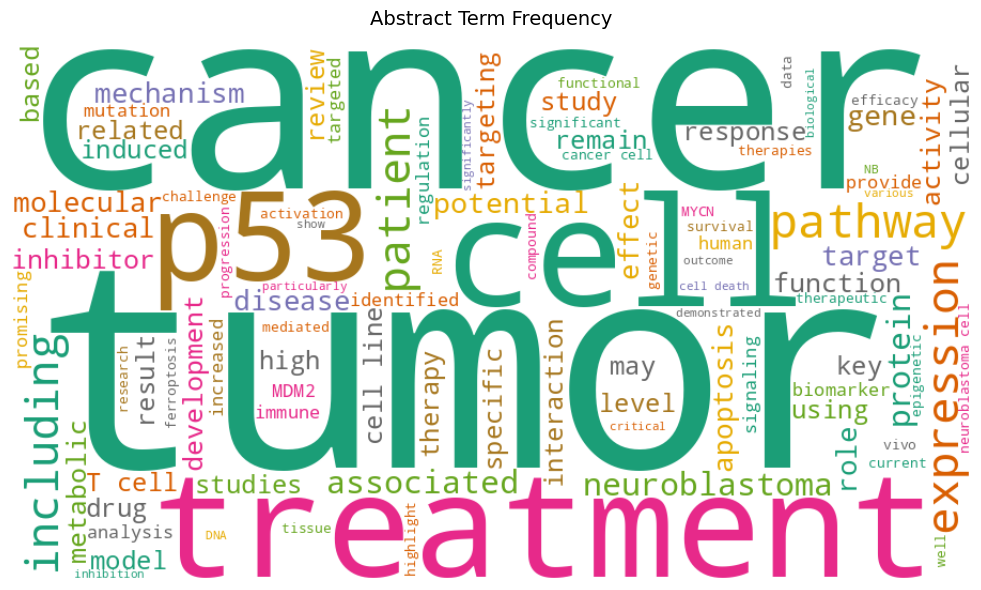

In [28]:
# Combine all abstracts (skip empty ones)
all_abstracts = ' '.join([
    paper.get('abstract', '') for paper in processed_papers 
    if paper.get('abstract', '').strip()
])

# Generate the word cloud
wordcloud = WordCloud(
    width=900, 
    height=500, 
    background_color='white',
    colormap='Dark2',  # Different color to distinguish
    max_words=100,
    contour_width=1,
    contour_color='#2ca02c',
    random_state=42
).generate(all_abstracts)

# Plot it
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(wordcloud, interpolation='bilinear')
ax.axis('off')
ax.set_title('Abstract Term Frequency', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig('./data/figure01_abstract_wordcloud.png', dpi=600, bbox_inches='tight')
plt.show()

The word cloud gives a quick snapshot of the main topics across the abstracts. The largest terms are cancer, tumor, cell, treatment, and p53, which is exactly what we would expect for a dataset focused on p53 targeted neuroblastoma research. Other frequent words like resistance, apoptosis, and expression also show up, reinforcing the relevance of the collected papers to our research question. Overall, the abstracts seem to cover the right themes.

### ◇ Entity Extraction Results

The second figure is a pie chart that shows the distribution of entity types extracted across all the papers. That should be a good way to see whether the models are picking up the kinds of biological terms we care about, mostly proteins and genes with some diseases and chemicals mixed in.

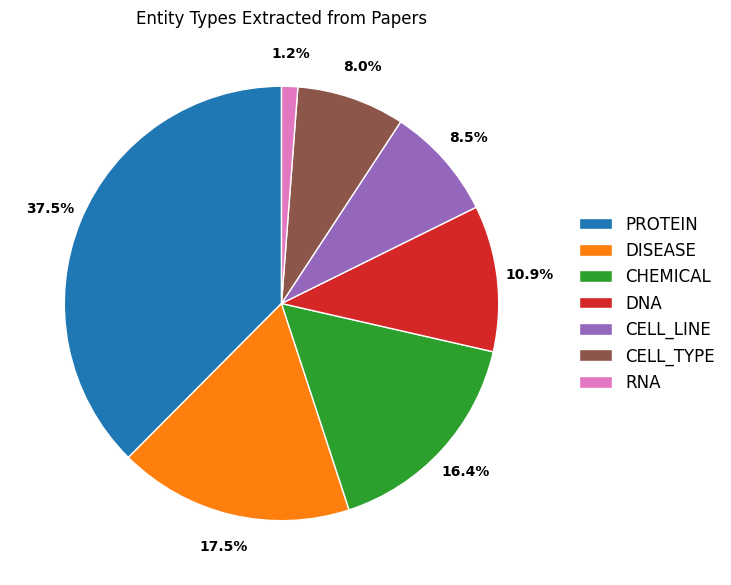

In [29]:
# Collect all entity labels and count how many times each appears across all papers
entity_labels = {}
for paper in ner_papers:
    for ent in paper.get('entities', []):
        label = ent.get('label', 'Unknown')
        entity_labels[label] = entity_labels.get(label, 0) + 1

# Sort entity types from most to least frequent so the pie chart is ordered nicely
labels = dict(sorted(entity_labels.items(), key=lambda x: x[1], reverse=True))

# Set up the figure for the pie chart
fig, ax = plt.subplots(figsize=(7, 6))

# Draw the pie chart with percentages outside the slices for clarity
wedges, _, autotexts = ax.pie(
    labels.values(),
    labels=None, # Hide the labels on the pie itself
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.tab10.colors[:len(labels)],
    pctdistance=1.15,            # Push percentage labels outside the pie
    wedgeprops={'edgecolor': 'white', 'linewidth': 1}
)

# Make the percentage text more readable with a white background box
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_weight('bold')
    autotext.set_bbox(dict(
        facecolor='white',
        edgecolor='none',
        alpha=0.8,
        pad=0.3
    ))

# Add a clean legend to the side so we know which color corresponds to which entity type
ax.legend(
    wedges,
    labels.keys(),
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=12,
    frameon=False
)

ax.set_title("Entity Types Extracted from Papers")

# Tighten the layout and save the image
plt.tight_layout()
plt.savefig("./data/figure02_entity_distribution.png", dpi=600, bbox_inches="tight")
plt.show()

The entity distribution is pretty much what I expected. Proteins dominate at 37.5%, which makes sense given we are looking at p53 and its interactions. Diseases and chemicals are also well represented at around 17.5% and 16.4%, which makes sense given the neuroblastoma focus and the drugs being discussed in the papers. DNA, cell lines, and cell types are lower, which is fine since the models are picking up relevant biological terms rather than experimental artifacts. RNA barely registers, which is interesting but not surprising given the text is more about proteins and pathways than non-coding RNA or cell classification. Overall the NER models are picking up the right kinds of terms, though the bias toward proteins is pretty clear.

### ◇ Relation Extraction Overview

The third figure shows the frequency of each relation type extracted by the PubMedBERT model.\
This gives me a sense of what kinds of relationships the model is picking up.

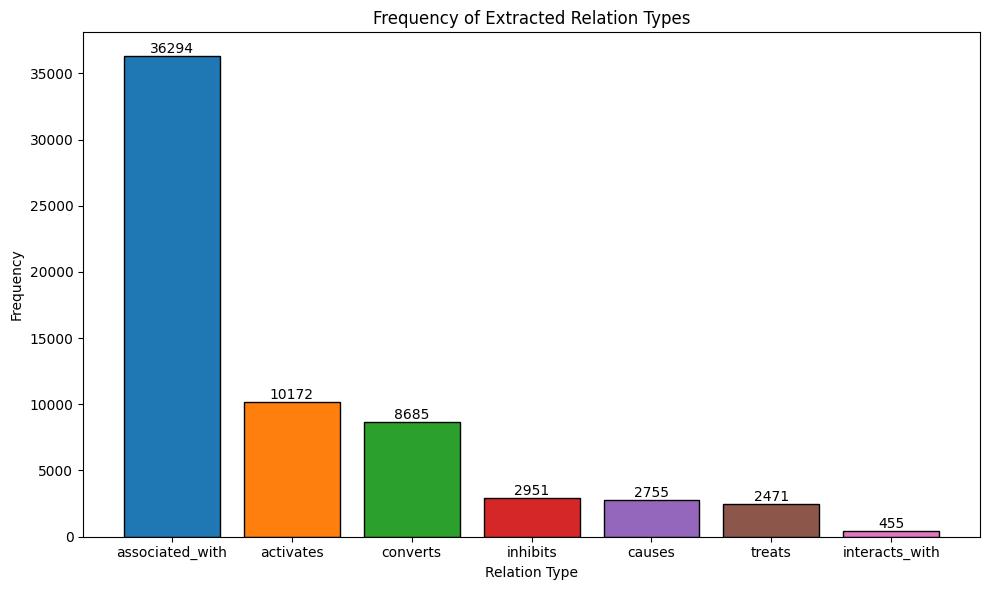

In [22]:
# Count up how many times each relation type appears across all papers
rel_types = {}
for paper in relation_papers:
    for rel in paper.get('relations', []):
        rel_type = rel[1]
        rel_types[rel_type] = rel_types.get(rel_type, 0) + 1

# Order from most to least frequent
sorted_rels = dict(sorted(rel_types.items(), key=lambda x: x[1], reverse=True))

# Set up a bar chart with a different color for each bar
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.tab10.colors[:len(sorted_rels)]  # 10 distinct colors
bars = ax.bar(sorted_rels.keys(), sorted_rels.values(), color=colors, 
              edgecolor='black', linewidth=1)

ax.set_ylabel('Frequency')
ax.set_xlabel('Relation Type')
ax.set_title('Frequency of Extracted Relation Types')

# Add count numbers on top of each bar
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.4,
                f'{int(height)}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('./data/figure03_relation_types.png', dpi=600)
plt.show()

The relation type distribution is pretty predictable. "associated_with" dominates at over 36,000 relations, which makes sense since it is the default catch all when the model detects a connection but cannot pin down a more specific mechanism. "activates" and "converts" are next at around 10,000 and 8,600, which fits with p53 biology. The drop off after that is steep, with "inhibits", "causes", and "treats" all hovering around 2,500 to 3,000. "interacts_with" is weirdly low at only 455. So basically, the model defaults to "associated_with" when uncertain, which means I should take the finer grained relation types with a grain of salt.

---
## ◈ Close Neo4j

Now that the entire pipeline is finished, we can close the Neo4j connection.

In [23]:
driver.close()
print("Neo4j connection closed.")

Neo4j connection closed.


That wraps things up.

---
# **End**
---